In [3]:
from google.colab import files

uploaded = files.upload()

Saving Archive.zip to Archive.zip


In [4]:
import os
import zipfile

DATA_DIR = "/content/olist_data"
os.makedirs(DATA_DIR, exist_ok=True)

zip_files = [f for f in uploaded if f.endswith(".zip")]

if zip_files:
    with zipfile.ZipFile(zip_files[0], "r") as zip_ref:
        zip_ref.extractall(DATA_DIR)
    print("Dataset extracted successfully!")
    print(os.listdir(DATA_DIR))
else:
    print("Please upload a ZIP file first.")

Dataset extracted successfully!
['olist_products_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_geolocation_dataset.csv', 'product_category_name_translation.csv', 'olist_customers_dataset.csv', 'olist_sellers_dataset.csv', 'olist_order_reviews_dataset.csv', '__MACOSX', 'olist_order_items_dataset.csv']


In [5]:
%pip install pyspark

In [6]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.regression import LinearRegression

spark = SparkSession.builder \
    .appName("CustomerIntelligenceSystem") \
    .master("local[*]") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")

print("Spark Version:", spark.version)
print("Spark started successfully!")

Spark Version: 4.0.4
Spark started successfully!


In [7]:
import os

files = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "products": "olist_products_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "categories": "product_category_name_translation.csv"
}

data = {}

for name, filename in files.items():
    path = os.path.join(DATA_DIR, filename)
    data[name] = spark.read.csv(path, header=True, inferSchema=True)
    print(name, data[name].count(), "rows")

customers 99441 rows
orders 99441 rows
items 112650 rows
products 32951 rows
payments 103886 rows
reviews 104162 rows
sellers 3095 rows
geolocation 1000163 rows
categories 71 rows


In [8]:
data["orders"].printSchema()
data["orders"].show(5, truncate=False)

data["customers"].printSchema()
data["items"].show(5, truncate=False)

root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)

+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|order_id                        |customer_id                     |order_status|order_purchase_timestamp|order_approved_at  |order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|
+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------

In [9]:
for name in data:
    data[name] = data[name].dropDuplicates()

orders = data["orders"].filter(F.col("order_id").isNotNull())
customers = data["customers"].filter(F.col("customer_id").isNotNull())
items = data["items"].filter(F.col("order_id").isNotNull())
products = data["products"].filter(F.col("product_id").isNotNull())
payments = data["payments"].filter(F.col("order_id").isNotNull())


In [10]:
customer_orders = orders.join(
    customers,
    on="customer_id",
    how="inner"
)

customer_orders.select(
    "order_id",
    "customer_id",
    "customer_city",
    "order_status",
    "order_purchase_timestamp"
).show(10, truncate=False)

+--------------------------------+--------------------------------+--------------+------------+------------------------+
|order_id                        |customer_id                     |customer_city |order_status|order_purchase_timestamp|
+--------------------------------+--------------------------------+--------------+------------+------------------------+
|6f6665c1d76e55561978ccb45bdcafc6|12ae89712aa5a178c22147486d3cd310|rio de janeiro|delivered   |2017-02-23 08:03:00     |
|5c1f2bd7eff419c165428371164d750c|ac4e328e156057d602bb4d7b146d5468|guarulhos     |delivered   |2018-03-08 15:59:11     |
|38971812f1db9e4a30885e5574dcbe53|735774ca9e99d1d85ae5f53b4958e6cc|ipatinga      |delivered   |2018-06-24 13:38:07     |
|28b2d19e3d604381f30089a68a4e0831|3d8cfa48830149a95028f6dc880e13eb|sao paulo     |delivered   |2018-04-29 14:31:40     |
|a611321b36103c43fd31f578c7c6e459|edfe8350920188f5738ab4ef3af21d62|belo horizonte|delivered   |2018-08-11 23:28:46     |
|654c6463f421d51939eae082dcc3b15

In [11]:
sales = items.join(
    orders.select("order_id", "customer_id", "order_status", "order_purchase_timestamp"),
    on="order_id",
    how="inner"
).filter(
    F.col("order_status") == "delivered"
)

sales = sales.withColumn(
    "order_purchase_timestamp",
    F.to_timestamp("order_purchase_timestamp")
).withColumn(
    "order_month",
    F.date_format("order_purchase_timestamp", "yyyy-MM")
)

sales.select(
    "order_id",
    "product_id",
    "price",
    "freight_value",
    "order_month"
).show(10, truncate=False)

+--------------------------------+--------------------------------+------+-------------+-----------+
|order_id                        |product_id                      |price |freight_value|order_month|
+--------------------------------+--------------------------------+------+-------------+-----------+
|00ed64bc080d87b4ab7f0c433bc5e98f|fbb1cfc2810efabf3235eccf4530f4ae|44.9  |16.11        |2017-05    |
|048f4f6b6d2d3bc131665b2440c39f70|c075b8e131353552218860f1c421e4ef|48.9  |37.9         |2017-05    |
|048fec87f5858e3a91ce55d3a944b457|625218e2e2b4668a47d08911e0def1a4|42.42 |19.36        |2018-05    |
|054df8d1a5ab3cf520be20c25d98f5f4|87a71ae93900ab55fcf685c8040769b3|12.9  |17.06        |2018-05    |
|059bbeb3477ed66fd7e670c3f879009a|88722e1dbe9a41a0834374aaaf19ffd2|31.0  |11.85        |2017-07    |
|05ea901eba2a26661f43478b5c6b02d0|7cb2ff3193293db892fd5697aa99a19b|24.9  |16.11        |2017-11    |
|060b4964af74f7046c4bfd56ddeeb7e7|9d32095f76b97762307e86cfc18dd7a0|49.95 |18.45        |201

In [12]:
monthly_sales = sales.groupBy("order_month").agg(
    F.round(F.sum("price"), 2).alias("total_sales"),
    F.countDistinct("order_id").alias("total_orders"),
    F.round(F.avg("price"), 2).alias("average_item_price")
).orderBy("order_month")

monthly_sales.show(30, truncate=False)

+-----------+-----------+------------+------------------+
|order_month|total_sales|total_orders|average_item_price|
+-----------+-----------+------------+------------------+
|2016-09    |134.97     |1           |44.99             |
|2016-10    |40325.11   |265         |128.83            |
|2016-12    |10.9       |1           |10.9              |
|2017-01    |111798.36  |750         |122.45            |
|2017-02    |234223.4   |1653        |126.06            |
|2017-03    |359198.85  |2546        |123.99            |
|2017-04    |340669.68  |2303        |132.61            |
|2017-05    |489338.25  |3546        |122.21            |
|2017-06    |421923.37  |3135        |120.93            |
|2017-07    |481604.52  |3872        |109.06            |
|2017-08    |554699.7   |4193        |115.63            |
|2017-09    |607399.67  |4150        |128.22            |
|2017-10    |648247.65  |4478        |124.33            |
|2017-11    |987765.37  |7289        |116.55            |
|2017-12    |7

In [13]:
category_sales = sales.join(
    products.select("product_id", "product_category_name"),
    on="product_id",
    how="left"
).join(
    data["categories"],
    on="product_category_name",
    how="left"
)

category_sales.groupBy(
    F.coalesce(
        F.col("product_category_name_english"),
        F.col("product_category_name"),
        F.lit("Unknown")
    ).alias("category")
).agg(
    F.round(F.sum("price"), 2).alias("revenue"),
    F.countDistinct("order_id").alias("orders")
).orderBy(
    F.desc("revenue")
).show(10, truncate=False)

+---------------------+----------+------+
|category             |revenue   |orders|
+---------------------+----------+------+
|health_beauty        |1233131.72|8647  |
|watches_gifts        |1166176.98|5495  |
|bed_bath_table       |1023434.76|9272  |
|sports_leisure       |954852.55 |7530  |
|computers_accessories|888724.61 |6530  |
|furniture_decor      |711927.69 |6307  |
|housewares           |615628.69 |5743  |
|cool_stuff           |610204.1  |3559  |
|auto                 |578966.65 |3810  |
|toys                 |471286.48 |3804  |
+---------------------+----------+------+
only showing top 10 rows


In [14]:
sales.createOrReplaceTempView("sales")
orders.createOrReplaceTempView("orders")
customers.createOrReplaceTempView("customers")

In [15]:
spark.sql("""
SELECT
    order_month,
    ROUND(SUM(price), 2) AS total_revenue,
    COUNT(DISTINCT order_id) AS total_orders
FROM sales
GROUP BY order_month
ORDER BY order_month
""").show(30, truncate=False)

+-----------+-------------+------------+
|order_month|total_revenue|total_orders|
+-----------+-------------+------------+
|2016-09    |134.97       |1           |
|2016-10    |40325.11     |265         |
|2016-12    |10.9         |1           |
|2017-01    |111798.36    |750         |
|2017-02    |234223.4     |1653        |
|2017-03    |359198.85    |2546        |
|2017-04    |340669.68    |2303        |
|2017-05    |489338.25    |3546        |
|2017-06    |421923.37    |3135        |
|2017-07    |481604.52    |3872        |
|2017-08    |554699.7     |4193        |
|2017-09    |607399.67    |4150        |
|2017-10    |648247.65    |4478        |
|2017-11    |987765.37    |7289        |
|2017-12    |726033.19    |5513        |
|2018-01    |924645.0     |7069        |
|2018-02    |826437.13    |6555        |
|2018-03    |953356.25    |7003        |
|2018-04    |973534.09    |6798        |
|2018-05    |977544.69    |6749        |
|2018-06    |856077.86    |6099        |
|2018-07    |867

In [16]:
customer_features = sales.groupBy("customer_id").agg(
    F.countDistinct("order_id").alias("total_orders"),
    F.sum("price").alias("total_spending"),
    F.avg("price").alias("avg_item_price"),
    F.sum("freight_value").alias("total_freight")
)

customer_features = customer_features.fillna(0)

customer_features.show(10, truncate=False)

+--------------------------------+------------+--------------+--------------+-------------+
|customer_id                     |total_orders|total_spending|avg_item_price|total_freight|
+--------------------------------+------------+--------------+--------------+-------------+
|2daf50201a5e309f6be0fcb20ff2ddd5|1           |155.97        |155.97        |19.19        |
|36a1aa63bf2ebcd4911e026092700610|1           |86.99         |86.99         |11.81        |
|0721e1c4b91bc6ded6579edace8659d3|1           |89.9          |89.9          |17.88        |
|9a5d390630499694895f2d2357a9967e|1           |224.1         |224.1         |19.46        |
|c79c8d356d92bb1b74efb6c4a7766527|1           |102.28        |102.28        |13.27        |
|80447be02d8f3f3f309c7df938a08501|1           |25.9          |25.9          |15.1         |
|1187acd131fe97cfc7cde033a4f036dd|1           |30.0          |30.0          |16.11        |
|a836f6725983cd79994904405fc070aa|1           |31.5          |15.75         |21.

In [17]:
assembler = VectorAssembler(
    inputCols=[
        "total_orders",
        "total_spending",
        "avg_item_price",
        "total_freight"
    ],
    outputCol="raw_features"
)

customer_vectors = assembler.transform(customer_features)

scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="features",
    withMean=True,
    withStd=True
)

scaler_model = scaler.fit(customer_vectors)
customer_vectors = scaler_model.transform(customer_vectors)

In [18]:
kmeans = KMeans(
    k=4,
    seed=42,
    featuresCol="features",
    predictionCol="cluster"
)

kmeans_model = kmeans.fit(customer_vectors)
segmented_customers = kmeans_model.transform(customer_vectors)

segmented_customers.select(
    "customer_id",
    "total_orders",
    "total_spending",
    "cluster"
).show(20, truncate=False)

+--------------------------------+------------+--------------+-------+
|customer_id                     |total_orders|total_spending|cluster|
+--------------------------------+------------+--------------+-------+
|2daf50201a5e309f6be0fcb20ff2ddd5|1           |155.97        |0      |
|36a1aa63bf2ebcd4911e026092700610|1           |86.99         |0      |
|0721e1c4b91bc6ded6579edace8659d3|1           |89.9          |0      |
|9a5d390630499694895f2d2357a9967e|1           |224.1         |0      |
|c79c8d356d92bb1b74efb6c4a7766527|1           |102.28        |0      |
|80447be02d8f3f3f309c7df938a08501|1           |25.9          |0      |
|1187acd131fe97cfc7cde033a4f036dd|1           |30.0          |0      |
|a836f6725983cd79994904405fc070aa|1           |31.5          |0      |
|6e48d7670ed33717bfa54a210ca49c35|1           |116.99        |0      |
|21fbc9ed5116c69ccb4ee2c301b9d518|1           |89.99         |0      |
|5396ffb28b2d1cbea8d6ec46201f06ba|1           |139.94        |0      |
|6f804

In [19]:
cluster_summary = segmented_customers.groupBy("cluster").agg(
    F.count("*").alias("customer_count"),
    F.round(F.avg("total_spending"), 2).alias("avg_spending"),
    F.round(F.avg("total_orders"), 2).alias("avg_orders"),
    F.round(F.avg("avg_item_price"), 2).alias("avg_item_price")
).orderBy("cluster")

cluster_summary.show(truncate=False)

+-------+--------------+------------+----------+--------------+
|cluster|customer_count|avg_spending|avg_orders|avg_item_price|
+-------+--------------+------------+----------+--------------+
|0      |85687         |90.13       |1.0       |84.13         |
|1      |787           |1678.66     |1.0       |1564.74       |
|2      |3433          |308.09      |1.0       |201.15        |
|3      |6571          |474.79      |1.0       |449.23        |
+-------+--------------+------------+----------+--------------+



In [20]:
from pyspark.ml.evaluation import RegressionEvaluator

prediction_data = customer_features.filter(
    (F.col("total_spending") >= 0) &
    (F.col("total_orders") > 0)
)

assembler_lr = VectorAssembler(
    inputCols=["total_orders", "avg_item_price", "total_freight"],
    outputCol="features"
)

lr_data = assembler_lr.transform(prediction_data).select(
    "features",
    F.col("total_spending").alias("label")
)

train_data, test_data = lr_data.randomSplit([0.8, 0.2], seed=42)

lr = LinearRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=50,
    regParam=0.1
)

lr_model = lr.fit(train_data)
predictions = lr_model.transform(test_data)

predictions.select("label", "prediction").show(10, truncate=False)

+------------------+-------------------+
|label             |prediction         |
+------------------+-------------------+
|3.0               |2.9287704315754226 |
|3.85              |-3.3508818516472605|
|3.9               |7.09251854781704   |
|28.680000000000003|121.04431114212834 |
|9.98              |20.374524419725457 |
|5.2               |8.368794434192314  |
|5.5               |8.663319638740454  |
|5.9               |-1.3382929539016395|
|5.99              |7.724389376473326  |
|5.99              |9.14437747283575   |
+------------------+-------------------+
only showing top 10 rows


In [21]:
rmse = RegressionEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="rmse"
).evaluate(predictions)

mae = RegressionEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="mae"
).evaluate(predictions)

r2 = RegressionEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="r2"
).evaluate(predictions)

print("RMSE:", round(rmse, 2))
print("MAE:", round(mae, 2))
print("R2 Score:", round(r2, 4))

RMSE: 52.89
MAE: 17.83
R2 Score: 0.932


In [22]:
from pyspark.sql.functions import col

product_pairs = items.select(
    "order_id",
    col("product_id").alias("product_a")
).join(
    items.select(
        "order_id",
        col("product_id").alias("product_b")
    ),
    on="order_id"
).filter(
    col("product_a") < col("product_b")
)

recommendations = product_pairs.groupBy(
    "product_a", "product_b"
).agg(
    F.count("*").alias("times_bought_together")
).orderBy(
    F.desc("times_bought_together")
)

recommendations.show(10, truncate=False)

+--------------------------------+--------------------------------+---------------------+
|product_a                       |product_b                       |times_bought_together|
+--------------------------------+--------------------------------+---------------------+
|05b515fdc76e888aada3c6d66c201dff|270516a3f41dc035aa87d220228f844c|100                  |
|36f60d45225e60c7da4558b070ce4b60|e53e557d5a159f5aa2c5e995dfdf244b|48                   |
|62995b7e571f5760017991632bbfd311|ac1ad58efc1ebf66bfadc09f29bdedc0|36                   |
|710b7c26b7a742f497bba45fab91a25f|a9d9db064d4afd4458eb3e139fe29167|36                   |
|35afc973633aaeb6b877ff57b2793310|99a4788cb24856965c36a24e339b6058|30                   |
|308e4e21ae228a10f6370a243ae59995|90b58782fdd04cb829667fcc41fb65f5|30                   |
|2ef36e1cae01b86d0ff0a2f50ff2bd53|53759a2ecddad2bb87a079a1f1519f73|30                   |
|18486698933fbb64af6c0a255f7dd64c|dbb67791e405873b259e4656bf971246|26                   |
|58efb9b63

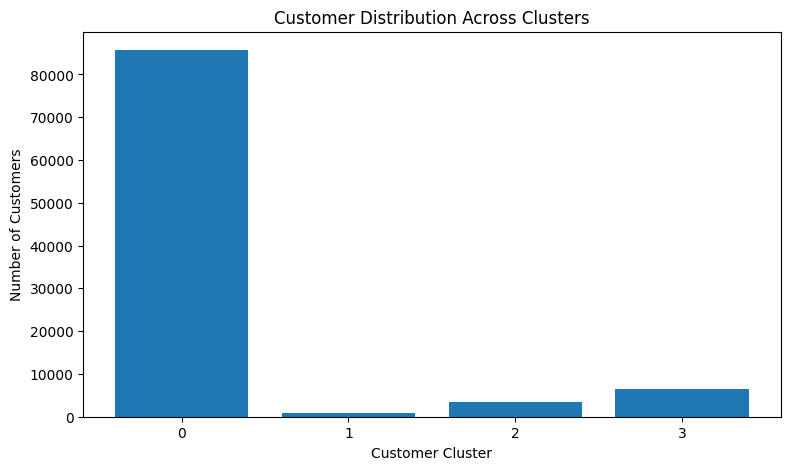

In [23]:
import matplotlib.pyplot as plt

cluster_pd = cluster_summary.toPandas()

plt.figure(figsize=(9, 5))
plt.bar(
    cluster_pd["cluster"].astype(str),
    cluster_pd["customer_count"]
)
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.title("Customer Distribution Across Clusters")
plt.show()

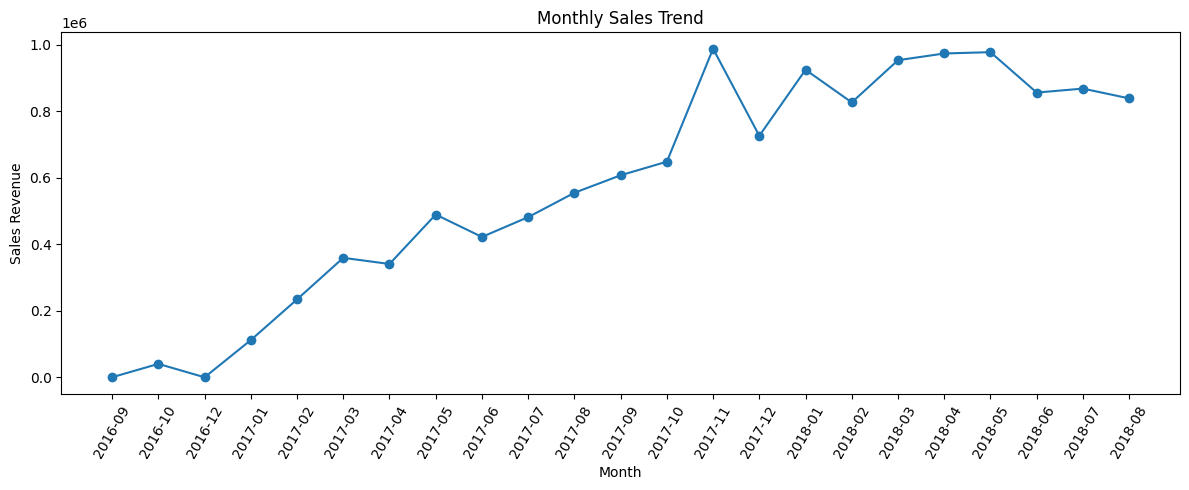

In [24]:
monthly_pd = monthly_sales.toPandas()

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_pd["order_month"],
    monthly_pd["total_sales"],
    marker="o"
)
plt.xlabel("Month")
plt.ylabel("Sales Revenue")
plt.title("Monthly Sales Trend")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [25]:
import time
import pandas as pd

benchmark_data = sales.select(
    "order_month", "price"
).dropna()

pandas_data = benchmark_data.toPandas()

start = time.perf_counter()

spark_result = benchmark_data.groupBy("order_month").agg(
    F.sum("price").alias("revenue"),
    F.count("*").alias("items_sold")
).collect()

spark_time = time.perf_counter() - start

start = time.perf_counter()

pandas_result = pandas_data.groupby("order_month").agg(
    revenue=("price", "sum"),
    items_sold=("price", "count")
)

pandas_time = time.perf_counter() - start

print("Spark processing time:", round(spark_time, 4), "seconds")
print("Pandas processing time:", round(pandas_time, 4), "seconds")
print("Rows processed:", len(pandas_data))

Spark processing time: 3.4501 seconds
Pandas processing time: 0.0372 seconds
Rows processed: 110197


In [26]:
total_customers = customer_features.count()
total_orders = orders.count()
total_products = products.count()
total_revenue = sales.agg(
    F.round(F.sum("price"), 2).alias("revenue")
).first()["revenue"]

print("PROJECT SUMMARY")
print("-----------------------------")
print("Total Customers:", total_customers)
print("Total Orders:", total_orders)
print("Total Products:", total_products)
print("Delivered Order Revenue:", total_revenue)
print("Customer Clusters:", segmented_customers.select("cluster").distinct().count())
print("Recommendation Pairs:", recommendations.count())
print("Spark Version:", spark.version)

PROJECT SUMMARY
-----------------------------
Total Customers: 96478
Total Orders: 99441
Total Products: 32951
Delivered Order Revenue: 13221498.11
Customer Clusters: 4
Recommendation Pairs: 4058
Spark Version: 4.0.4


In [27]:
import os

OUTPUT_DIR = "/content/project_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

monthly_sales.toPandas().to_csv(
    f"{OUTPUT_DIR}/monthly_sales.csv", index=False
)

cluster_summary.toPandas().to_csv(
    f"{OUTPUT_DIR}/customer_clusters.csv", index=False
)

predictions.select(
    "label", "prediction"
).toPandas().to_csv(
    f"{OUTPUT_DIR}/spending_predictions.csv", index=False
)

recommendations.limit(100).toPandas().to_csv(
    f"{OUTPUT_DIR}/product_recommendations.csv", index=False
)

print("Project outputs saved successfully!")
print(os.listdir(OUTPUT_DIR))

Project outputs saved successfully!
['monthly_sales.csv', 'product_recommendations.csv', 'customer_clusters.csv', 'spending_predictions.csv']
